# Bagging Exercises

![Bagging.png](Assets/Bagging.png)

# Цели обучения

- Установить связь между понятиями «бутстреппинга» и «агрегирования» (более известного как «баггинг») для снижения дисперсии
- Применять алгоритм «Случайного леса», который позволяет ещё больше снизить корреляцию, наблюдаемую в моделях, построенных методом баггинга


## Введение

Для выполнения заданий на этой неделе мы будем использовать данные об оттоке клиентов из телекоммуникационной отрасли, которые мы рассматривали на первой неделе. Файл данных называется `Orange_Telecom_Churn_Data.csv`.

In [1]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix



## Вопрос 1

* Импортируйте данные об оттоке клиентов, содержащиеся в файле `Orange_Telecom_Churn_Data.csv`.
* Удалите все столбцы, которые, вероятно, не будут использоваться для прогнозирования.
* Осуществите соответствующее кодирование типов данных.

In [4]:
import pandas as pd

# Загрузка данных
df = pd.read_csv('Orange_Telecom_Churn_Data.csv')

# Удаление ненужных столбцов
# 'state' и 'area_code' часто удаляют, так как они могут создавать шум или переобучение
# 'phone_number' - уникальный идентификатор, не несет предсказательной силы
cols_to_drop = ['state', 'area_code', 'phone_number']
df = df.drop(columns=cols_to_drop)

# Кодирование булевых признаков
# Преобразуем 'yes'/'no' в True/False
df['intl_plan'] = df['intl_plan'].map({'yes': True, 'no': False})
df['voice_mail_plan'] = df['voice_mail_plan'].map({'yes': True, 'no': False})

# Проверка типов
print(df.dtypes)

account_length                     int64
intl_plan                           bool
voice_mail_plan                     bool
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object


В прогнозе ни в коем случае не должно фигурировать номер телефона. И вряд ли потребуются код города или штат, если только нет оснований полагать, что модель учитывает какой-то очень конкретный географический фактор.

Проанализируйте типы данных. Всё выглядит нормально, за исключением того, что `int_plan` и `voice_mail_plan` необходимо кодировать как булевы значения.

## Вопрос 2

* Проанализируйте распределение прогнозируемой переменной (`churned`).
* Разделите данные на обучающую и тестовую выборки. На основании распределения решите, следует ли использовать стратифицированное деление.
* Проанализируйте распределение предикторной переменной в обучающих и тестовых данных.

In [5]:
from sklearn.model_selection import train_test_split

# Анализ распределения
print("Распределение целевой переменной:")
print(df['churned'].value_counts(normalize=True))

# Разделение данных
X = df.drop('churned', axis=1)
y = df['churned']

# Используем stratify=y, так как классы несбалансированы (оттоков меньше)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Проверка распределения в выборках
print("Train distribution:", y_train.value_counts(normalize=True))
print("Test distribution:", y_test.value_counts(normalize=True))

Распределение целевой переменной:
churned
False    0.8586
True     0.1414
Name: proportion, dtype: float64
Train distribution: churned
False    0.858571
True     0.141429
Name: proportion, dtype: float64
Test distribution: churned
False    0.858667
True     0.141333
Name: proportion, dtype: float64


Учитывая асимметрию переменной-предиктора, давайте разбиваем данные, стратифицировав значения *churned*.

## Вопрос 3

* Постройте модели «случайного леса» с различным количеством деревьев и оцените ошибку «out-of-bag» для каждой из этих моделей.
* Постройте график полученных ошибок «out-of-bag» в зависимости от количества деревьев.

*Подсказка:* поскольку изменяется только количество деревьев, можно использовать флаг `warm_start`, чтобы модель каждый раз просто добавляла новые деревья к существующей модели. Для обновления количества деревьев используйте метод `set_params`.

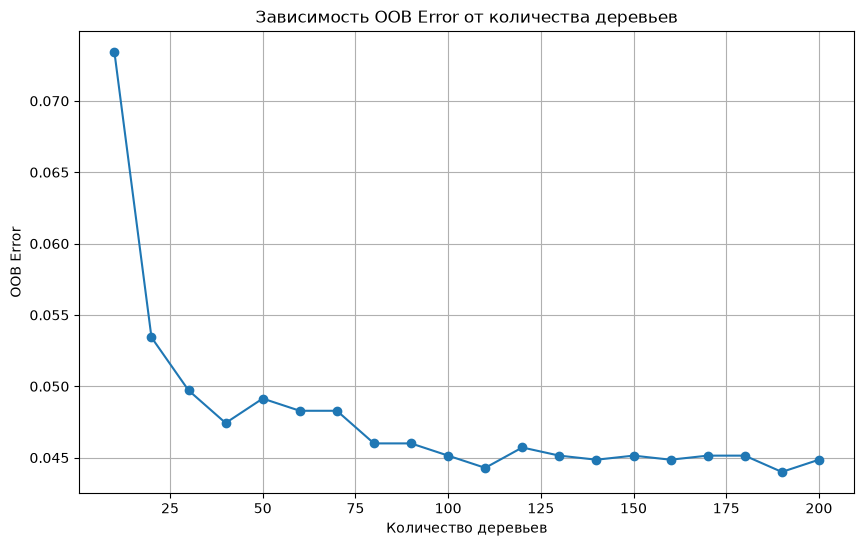

In [6]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import warnings

# Отключаем предупреждения о количестве деревьев
warnings.filterwarnings("ignore", category=UserWarning)

# Инициализация модели с warm_start
rf = RandomForestClassifier(warm_start=True, oob_score=True, random_state=42)

oob_errors = []
tree_range = range(10, 201, 10) # От 10 до 200 деревьев

for n_trees in tree_range:
    rf.set_params(n_estimators=n_trees)
    rf.fit(X_train, y_train)
    # Ошибка = 1 - OOB Score
    oob_errors.append(1 - rf.oob_score_)

# Построение графика
plt.figure(figsize=(10, 6))
plt.plot(tree_range, oob_errors, marker='o')
plt.title('Зависимость OOB Error от количества деревьев')
plt.xlabel('Количество деревьев')
plt.ylabel('OOB Error')
plt.grid(True)
plt.show()

Похоже, что количество ошибок стабилизировалось на уровне 100–150 деревьев.

## Вопрос 4

* Повторите задание из вопроса 3, используя дополнительные рандомизированные деревья (`ExtraTreesClassifier`). Обратите внимание, что для этой модели параметр `bootstrap` необходимо установить в значение `True`.
* Сравните ошибки метода «out-of-bag» для двух различных типов моделей.

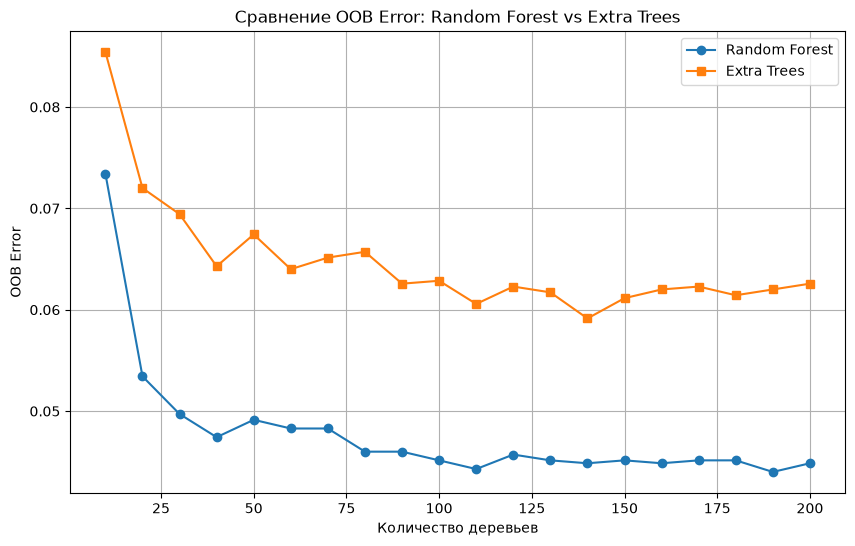

    n_estimators  Random Forest OOB Error  Extra Trees OOB Error
0             10                 0.073429               0.085429
1             20                 0.053429               0.072000
2             30                 0.049714               0.069429
3             40                 0.047429               0.064286
4             50                 0.049143               0.067429
5             60                 0.048286               0.064000
6             70                 0.048286               0.065143
7             80                 0.046000               0.065714
8             90                 0.046000               0.062571
9            100                 0.045143               0.062857
10           110                 0.044286               0.060571
11           120                 0.045714               0.062286
12           130                 0.045143               0.061714
13           140                 0.044857               0.059143
14           150         

In [7]:
from sklearn.ensemble import ExtraTreesClassifier
import pandas as pd

# Инициализация ExtraTreesClassifier с bootstrap=True
et = ExtraTreesClassifier(warm_start=True, oob_score=True, bootstrap=True, random_state=42)

oob_errors_et = []

for n_trees in tree_range:
    et.set_params(n_estimators=n_trees)
    et.fit(X_train, y_train)
    oob_errors_et.append(1 - et.oob_score_)

# Создание DataFrame для сравнения
results = pd.DataFrame({
    'n_estimators': tree_range,
    'Random Forest OOB Error': oob_errors,
    'Extra Trees OOB Error': oob_errors_et
})

# Построение сравнительного графика
plt.figure(figsize=(10, 6))
plt.plot(results['n_estimators'], results['Random Forest OOB Error'], marker='o', label='Random Forest')
plt.plot(results['n_estimators'], results['Extra Trees OOB Error'], marker='s', label='Extra Trees')
plt.title('Сравнение OOB Error: Random Forest vs Extra Trees')
plt.xlabel('Количество деревьев')
plt.ylabel('OOB Error')
plt.legend()
plt.grid(True)
plt.show()

print(results)

Объедините два датафрейма в один, чтобы упростить построение графиков.

Модель «случайного леса» демонстрирует стабильно более высокую эффективность по сравнению с моделью «дополнительных рандомизированных деревьев».

## Вопрос 5

* Выберите одну из моделей, демонстрирующих хорошие результаты, и рассчитайте показатели ошибок и матрицу путаницы на тестовом наборе данных.
* Учитывая распределение предсказанных классов, какой показатель является наиболее важным? А какой может вводить в заблуждение?

In [ ]:
В условиях дисбаланса классов (оттоков меньше), Accuracy (Точность) может вводить в заблуждение. 
Если модель будет всегда предсказывать "не ушел" (False), она будет иметь высокую точность, но будет бесполезна.
Наиболее важными показателями здесь являются Recall (Полнота/Воспроизведение) для класса True (насколько хорошо мы ловим уходящих клиентов) и F1-score (баланс между точностью и полнотой).

In [8]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Предположим, что 'rf' - это наша лучшая обученная модель (Random Forest) из вопроса 3/4
# Делаем предсказания на тестовой выборке
y_pred = rf.predict(X_test)

# Расчет показателей
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.9606666666666667

Classification Report:
               precision    recall  f1-score   support

       False       0.96      0.99      0.98      1288
        True       0.95      0.76      0.85       212

    accuracy                           0.96      1500
   macro avg       0.96      0.88      0.91      1500
weighted avg       0.96      0.96      0.96      1500


Confusion Matrix:
 [[1280    8]
 [  51  161]]


Неудивительно, что показатель воспроизведения для класса «Ушедшие клиенты» (True) довольно низкий, поскольку их количество весьма невелико. Тем не менее, мы показываем лучшие результаты, чем при случайном угадывании: точность составляет 0,932 (против 0,85 при случайном угадывании).

## Вопрос 6

* Распечатайте или отобразите матрицу путаницы.
* Постройте кривые ROC-AUC и точность-воспроизводимость.
* Постройте график важности признаков.

Кривые ROC-AUC и «точность-охватываемость».

Важность признаков. Общая ежедневная стоимость является наиболее значимым предиктором оттока клиентов.

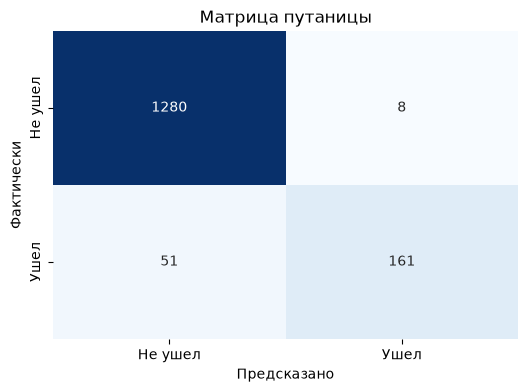

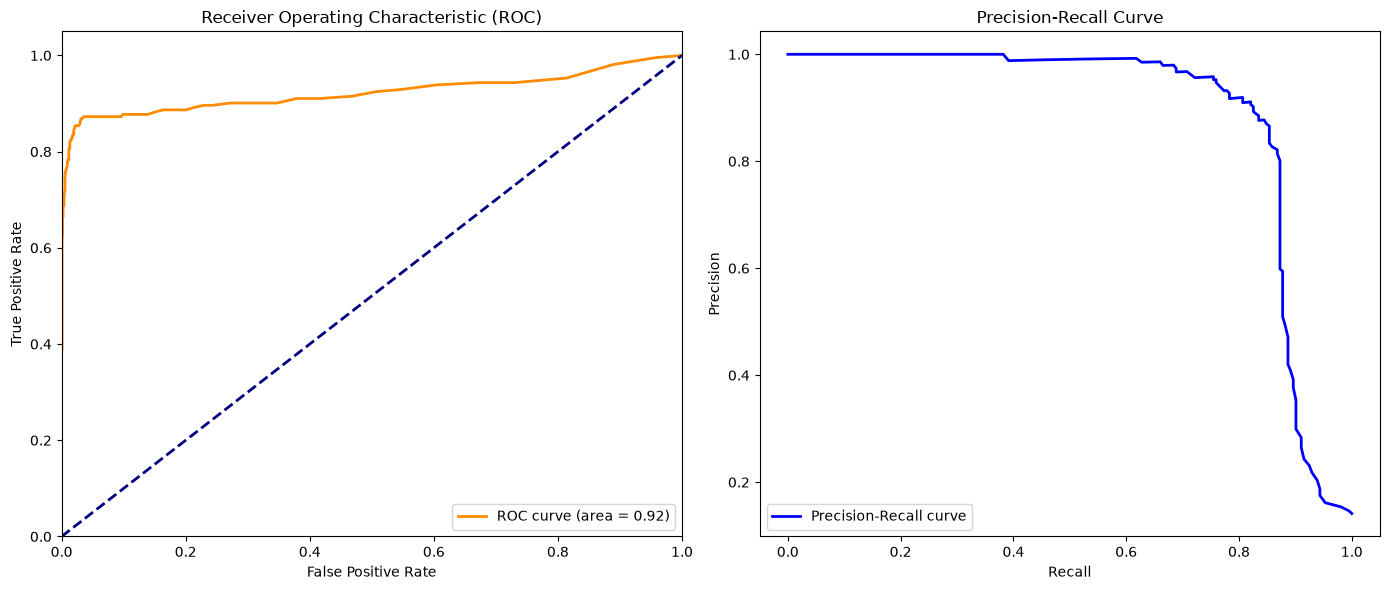

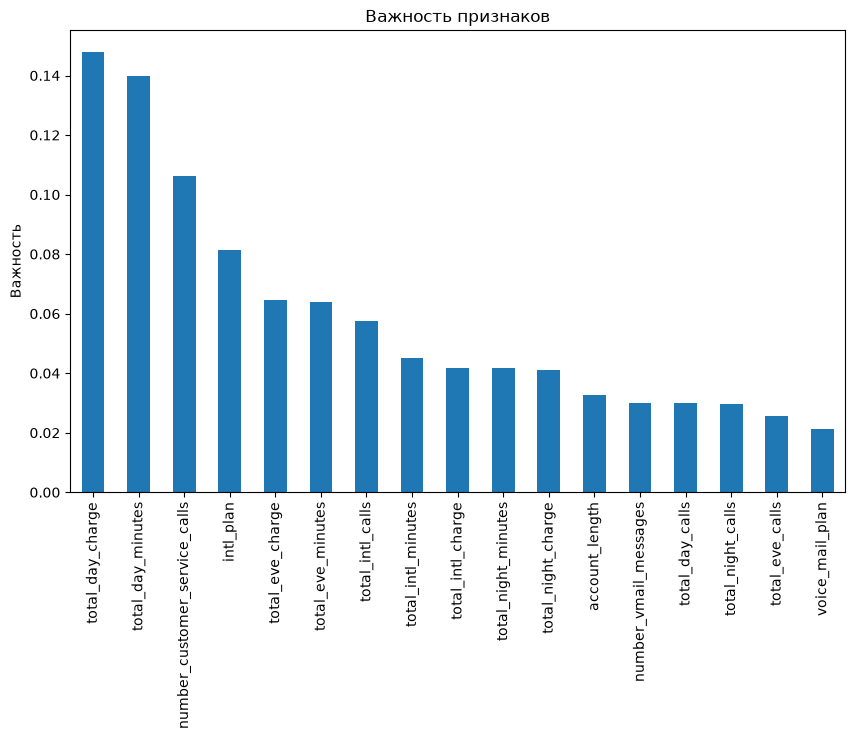

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# 1. Матрица путаницы (визуализация)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Не ушел', 'Ушел'], yticklabels=['Не ушел', 'Ушел'])
plt.xlabel('Предсказано')
plt.ylabel('Фактически')
plt.title('Матрица путаницы')
plt.show()

# 2. Кривые ROC-AUC и Precision-Recall
# Получаем вероятности предсказания для положительного класса
y_probs = rf.predict_proba(X_test)[:, 1]

# ROC кривая
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

# Precision-Recall кривая
precision, recall, _ = precision_recall_curve(y_test, y_probs)

# Построение графиков
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ROC
ax1.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
ax1.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('Receiver Operating Characteristic (ROC)')
ax1.legend(loc="lower right")

# Precision-Recall
ax2.plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve')
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

# 3. График важности признаков
feature_importances = pd.Series(rf.feature_importances_, index=X.columns)
feature_importances.sort_values(ascending=False).plot(kind='bar', figsize=(10, 6))
plt.title('Важность признаков')
plt.ylabel('Важность')
plt.show()